<a href="https://colab.research.google.com/github/SrijalSrivastava19/Data-Analytics/blob/main/Sprint_2/Sprint2_Solution_Simplified.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sprint 2: E-Commerce Data Analysis

### Data Collection | Data Cleaning | Exploratory Data Analysis | Visualization

This sprint focuses on collecting e-commerce product data,
cleaning and analyzing it, identifying price outliers,
and preparing a structured dataset for further analysis.

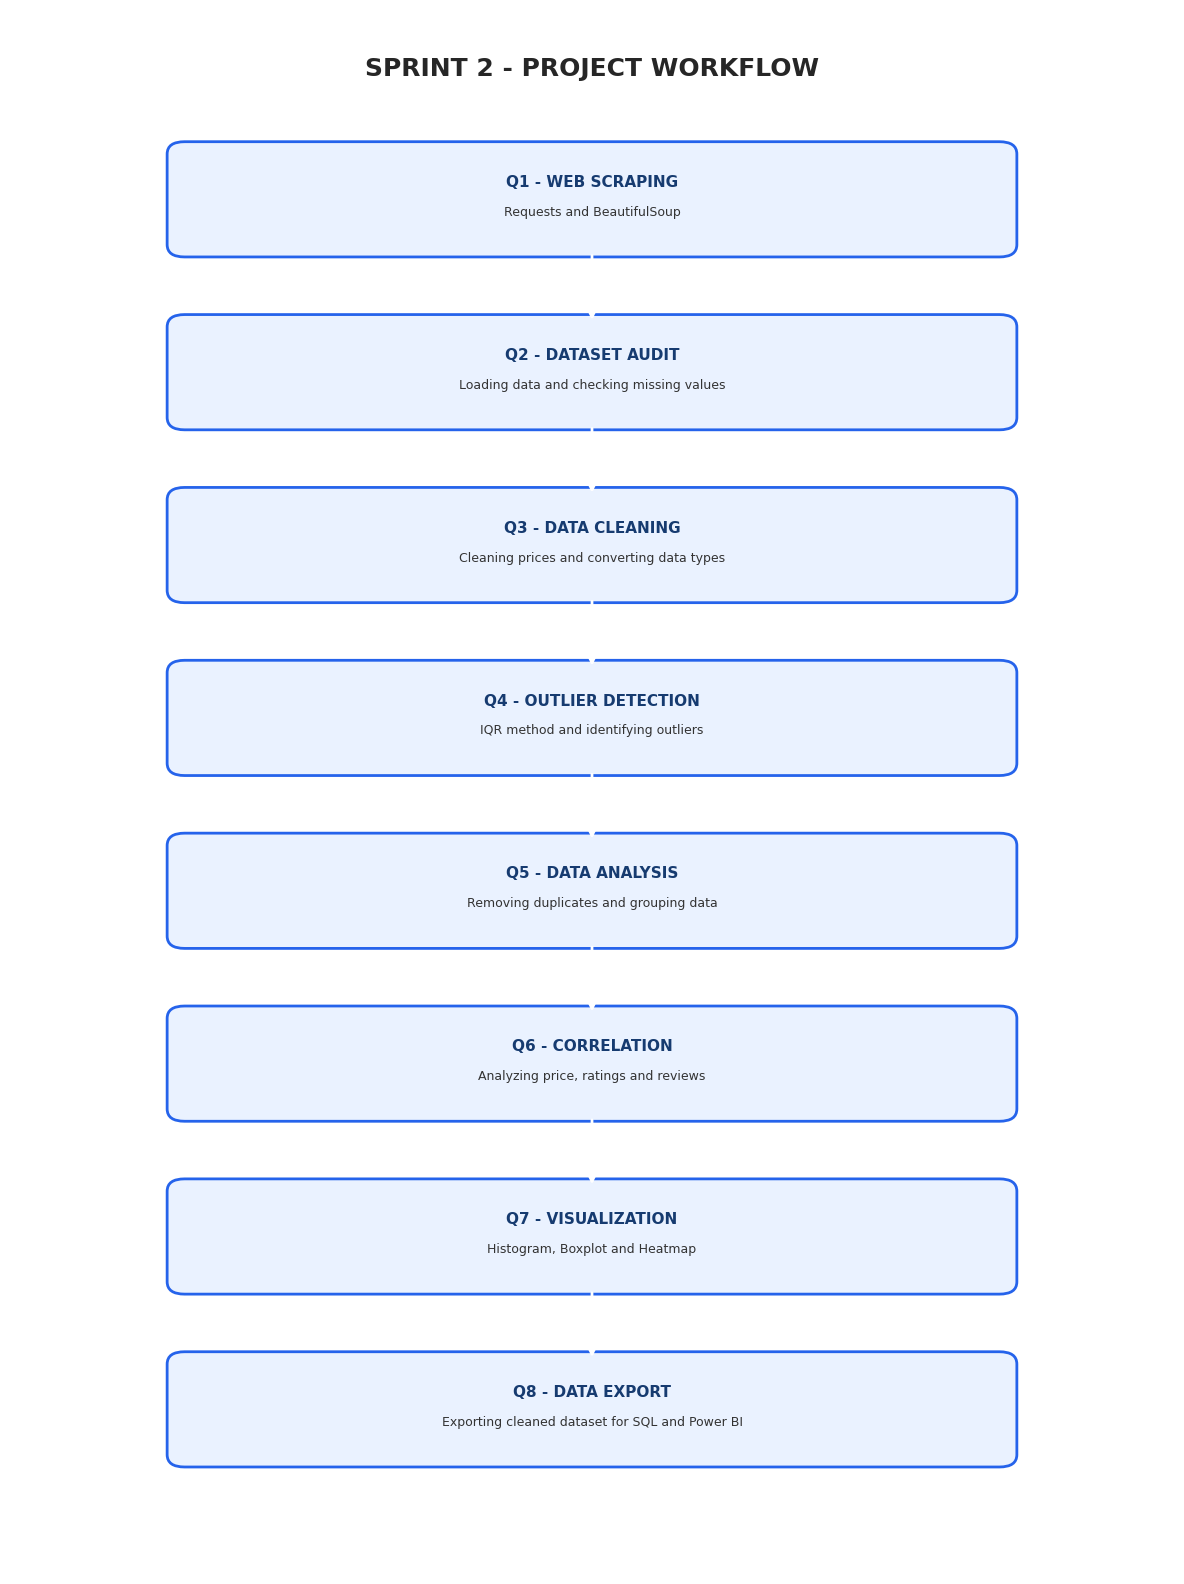

In [49]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [
    ("Q1 - WEB SCRAPING", "Requests and BeautifulSoup"),
    ("Q2 - DATASET AUDIT", "Loading data and checking missing values"),
    ("Q3 - DATA CLEANING", "Cleaning prices and converting data types"),
    ("Q4 - OUTLIER DETECTION", "IQR method and identifying outliers"),
    ("Q5 - DATA ANALYSIS", "Removing duplicates and grouping data"),
    ("Q6 - CORRELATION", "Analyzing price, ratings and reviews"),
    ("Q7 - VISUALIZATION", "Histogram, Boxplot and Heatmap"),
    ("Q8 - DATA EXPORT", "Exporting cleaned dataset for SQL and Power BI")
]

fig, ax = plt.subplots(figsize=(12, 16))
ax.set_xlim(0, 10)
ax.set_ylim(0, 19)
ax.axis("off")

ax.text(5, 18.2, "SPRINT 2 - PROJECT WORKFLOW",
        ha="center", fontsize=18, fontweight="bold")

for i, (title, desc) in enumerate(steps):
    y = 16.7 - i * 2.1

    box = FancyBboxPatch(
        (1.5, y - 0.55), 7, 1.1,
        boxstyle="round,pad=0.15",
        facecolor="#EAF2FF",
        edgecolor="#2563EB",
        linewidth=2
    )

    ax.add_patch(box)

    ax.text(5, y + 0.15, title,
            ha="center", fontsize=11,
            fontweight="bold", color="#163B70")

    ax.text(5, y - 0.2, desc,
            ha="center", fontsize=9, color="#333333")

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(5, y - 1.5),
            xytext=(5, y - 0.65),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

plt.tight_layout()
plt.show()


Q1: How do we scrape live product listings with BeautifulSoup?


In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [3]:
url = 'https://books.toscrape.com/catalogue/category/books_1/index.html'

headers = { "User-Agent" : "Mozilla/5.0"}
response = requests.get(url , headers =  headers , timeout = 10)

print("Status Code :",{ response.status_code})


Status Code : {200}


In [5]:
soup = BeautifulSoup(response.text , "html.parser")

first_card = soup.find("article", class_="product_pod")

In [8]:
rating_map = {"One" :1 , "Two" :2 , "Three":3 , "Four":4 , "Five":5 }

title = first_card.h3.a["title"]
price = first_card.find("p" , class_="price_color").text
rating_words = first_card.find("p", class_="star-rating")['class'][1]
rating_num = rating_map.get(rating_words,0)

In [9]:
print("Sample Scrapped Product:")
print(f"Title: {title}")
print(f"Price: {price}")
print(f"Rating:{rating_num}/5 stars ")

Sample Scrapped Product:
Title: A Light in the Attic
Price: Â£51.77
Rating:3/5 stars 


In [10]:
cards = soup.find_all("article", class_="product_pod")

all_books = []
for card in cards :
  all_books.append({
      "name":   card.h3.a["title"],
      "price":  card.find("p" , class_="price_color").text ,
      "rating": rating_map.get(card.find("p", class_="star-rating")['class'][1],0)
  })

df1 = pd.DataFrame(all_books)


In [11]:
df1

,name,price,rating
0,A Light in the Attic,Â£51.77,3
1,Tipping the Velvet,Â£53.74,1
2,Soumission,Â£50.10,1
3,Sharp Objects,Â£47.82,4
4,Sapiens: A Brief History of Humankind,Â£54.23,5
5,The Requiem Red,Â£22.65,1
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,4
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,3
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,4
9,The Black Maria,Â£52.15,1


Q2: How do we load our multi-category dataset and audit missing data?



In [12]:
df = pd.read_csv("/content/ecommerce_raw_scraped.csv")

df.head()

,listing_id,name,brand,category,price,rating,review_count,scraped_page
0,1,Maple Row Electric Kettle,Maple Row,home-goods,$23.29,3.7,1269.0,11
1,2,Lumen Air Purifier,Lumen,home-goods,186.52,2.9,2408.0,2
2,3,Maple Row Electric Kettle,Maple Row,home-goods,28.70,3.6,4135.0,2
3,4,Maple Row Wall Clock,Maple Row,home-goods,$127,4.7,859.0,5
4,5,Sonyx Mechanical Keyboard,Sonyx,electronics,USD 358.70,3.2,2823.0,2


In [13]:
df.isna().sum()

,0
listing_id,0
name,0
brand,0
category,0
price,6
rating,2
review_count,4
scraped_page,0


Q3: How do we clean messy currency strings?

In [14]:
df['price'].str.replace(r"[^0-9.]" , "" , regex=True)

,price
0,23.29
1,186.52
2,28.70
3,127
4,358.70
...,...
144,182.65
145,287.89
146,138.19
147,432.94


In [17]:
df['price'] = df['price'].str.replace(r"[^0-9.]", "", regex=True).astype(float)
df.head()

,listing_id,name,brand,category,price,rating,review_count,scraped_page
0,1,Maple Row Electric Kettle,Maple Row,home-goods,23.29,3.7,1269.0,11
1,2,Lumen Air Purifier,Lumen,home-goods,186.52,2.9,2408.0,2
2,3,Maple Row Electric Kettle,Maple Row,home-goods,28.70,3.6,4135.0,2
3,4,Maple Row Wall Clock,Maple Row,home-goods,127.00,4.7,859.0,5
4,5,Sonyx Mechanical Keyboard,Sonyx,electronics,358.70,3.2,2823.0,2


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   listing_id    149 non-null    int64  
 1   name          149 non-null    object 
 2   brand         149 non-null    object 
 3   category      149 non-null    object 
 4   price         143 non-null    float64
 5   rating        147 non-null    float64
 6   review_count  145 non-null    float64
 7   scraped_page  149 non-null    int64  
dtypes: float64(3), int64(2), object(3)
memory usage: 9.4+ KB


Q:4 How do we detect price outliers using the 1.5 x IQR rule?
Concept Pointers:
*   IQR(Interquaretile Range)= Q3(75th percentile)-Q1(25th percentile).
*   Upper Outlier Cutoff = Q3 + 1.5 x IQR.
*   Lower Outlier Cutoff = Q1 - 1.5 x IQR.   









In [20]:
df.describe()

,listing_id,price,rating,review_count,scraped_page
count,149.000000,143.000000,147.000000,145.000000,149.000000
mean,75.000000,207.131748,3.834694,2180.662069,6.006711
std,43.156691,278.109983,0.633067,1276.823033,3.433729
min,1.000000,10.000000,2.800000,18.000000,1.000000
25%,38.000000,78.410000,3.400000,919.000000,3.000000
50%,75.000000,163.940000,3.800000,2255.000000,6.000000
75%,112.000000,247.765000,4.400000,3368.000000,9.000000
max,149.000000,2580.280000,5.000000,4165.000000,12.000000


using the 1.5 x IQR rule ( interquartile range)

In [21]:
import numpy as np
def get_iqr(values):
  valid= values.dropna().values
  q25, q75 = np.percentile(valid, [25,75])
  iqr= q75-q25
  ub= q75+1.5*iqr
  return q25 , q75 , ub

In [30]:
for c, g in df.groupby("category"):
  q25, q75, ub = get_iqr(g["price"])
  outliers = g[g["price"] > ub]
  print(outliers)

    listing_id                    name        brand     category    price  \
14          15  Vantage Wireless Mouse    VANTAGE    electronics  2580.28   

    rating  review_count  scraped_page  
14     3.8        1200.0             1  
    listing_id                name      brand    category   price  rating  \
36          37  Lumen Air Purifier    LUMEN    home-goods  1363.0     4.8   

    review_count  scraped_page  
36          96.0             1  
    listing_id                          name         brand         category  \
81          82  PeakForm Hiking Backpack 40L    PEAKFORM    sports-outdoors   

      price  rating  review_count  scraped_page  
81  1675.26     3.0        3844.0             5  


Q5: How do we handle duplicate listings?

In [31]:
dup = df.duplicated().sum()

In [33]:
dup


np.int64(0)

Q6: Does higher product price correalte with customer ratings ?


In [41]:
corr = df[["price", "rating" , "review_count"]].corr()

In [42]:
corr

,price,rating,review_count
price,1.000000,-0.021552,-0.032520
rating,-0.021552,1.000000,-0.092349
review_count,-0.032520,-0.092349,1.000000


Q7: How do we visualize our findings with Seaborn and Matplotlib?


In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style= "whitegrid")


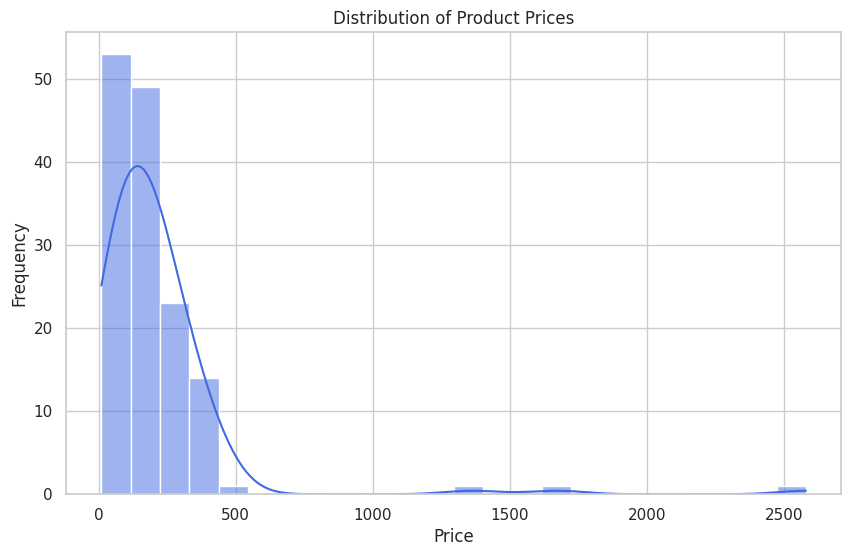

In [44]:
# Visual 1: Price Distribution Histogram

plt.figure(figsize=(10,6))
sns.histplot(df["price"],kde =True , color = "royalblue" )
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

/tmp/ipykernel_3280/1966513728.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x= "price", y="category" , data=df , palette ="Set2")


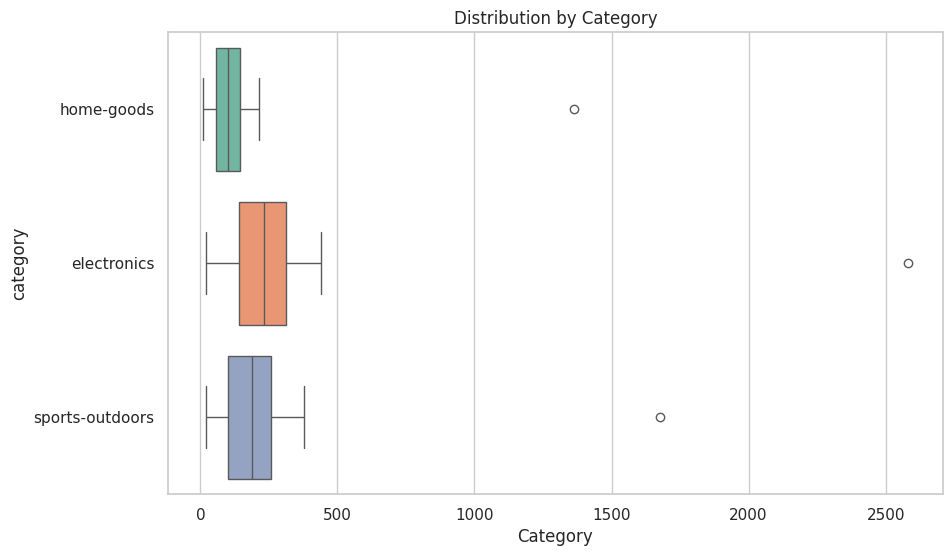

In [47]:
# Visual 2: Category Boxplot
plt.figure(figsize=(10,6))
sns.boxplot(x= "price", y="category" , data=df , palette ="Set2")
plt.title("Distribution by Category")
plt.xlabel("Category")

plt.show()

Q8: How do we export the cleaned dataset for downstream SQL and Power BI?

In [48]:
df.to_csv("cleaned_dataset.csv")